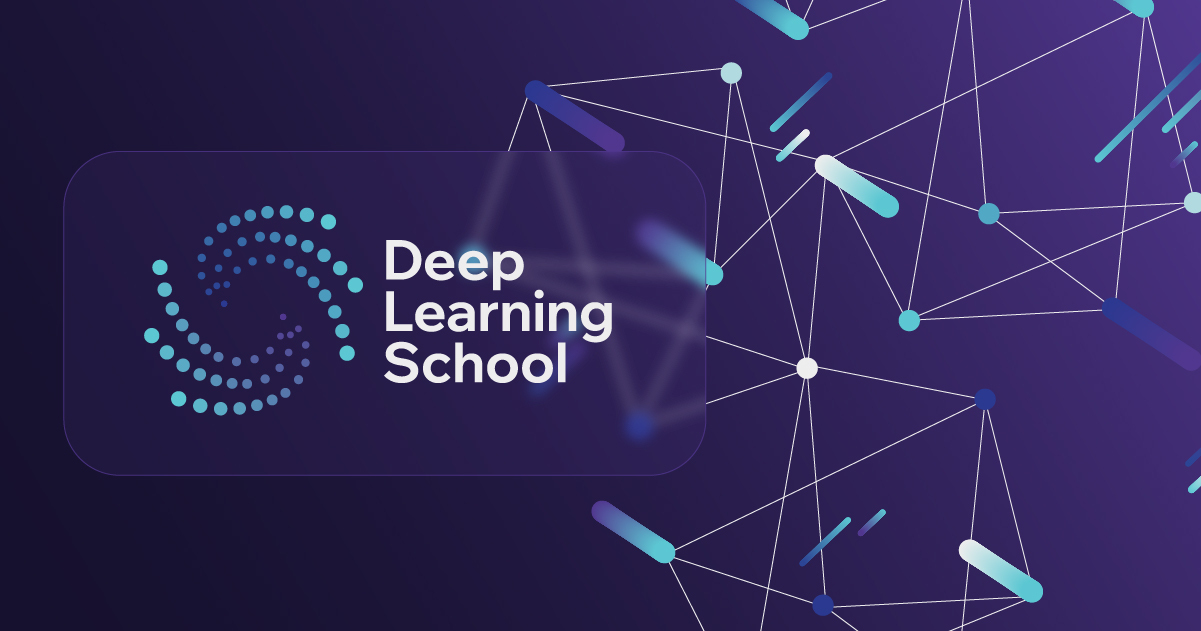

<h3 style="text-align: center;"><b>Школа глубокого обучения ФПМИ МФТИ</b></h3>

<h1 style="text-align: center;"><b>Домашнее задание. Обучение языковой модели с помощью LSTM </b></h1>


В этом задании Вам предстоит обучить языковую модель с помощью рекуррентной нейронной сети. В отличие от семинарского занятия, Вам необходимо будет работать с отдельными словами, а не буквами.


Установим модуль ```datasets```, чтобы нам проще было работать с данными.

In [2]:
!pip install datasets

Импорт необходимых библиотек

In [3]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from datasets import load_dataset
from nltk.tokenize import sent_tokenize, word_tokenize
from sklearn.model_selection import train_test_split
import nltk
#nltk.download('punkt_tab')

from collections import Counter
from typing import List

from operator import itemgetter
import itertools

import seaborn
seaborn.set(palette='summer')

In [4]:
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [5]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

## Подготовка данных

Воспользуемся датасетом imdb. В нем хранятся отзывы о фильмах с сайта imdb. Загрузим данные с помощью функции ```load_dataset```

In [6]:
# Загрузим датасет
dataset = load_dataset('stanfordnlp/imdb')

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

### Препроцессинг данных и создание словаря (1 балл)

Далее вам необходмо самостоятельно произвести препроцессинг данных и получить словарь или же просто ```set``` строк. Что необходимо сделать:

1. Разделить отдельные тренировочные примеры на отдельные предложения с помощью функции ```sent_tokenize``` из бибилиотеки ```nltk```. Каждое отдельное предложение будет одним тренировочным примером.
2. Оставить только те предложения, в которых меньше ```word_threshold``` слов.
3. Посчитать частоту вхождения каждого слова в оставшихся предложениях. Для деления предлоения на отдельные слова удобно использовать функцию ```word_tokenize```.
4. Создать объект ```vocab``` класса ```set```, положить в него служебные токены '\<unk\>', '\<bos\>', '\<eos\>', '\<pad\>' и vocab_size самых частовстречающихся слов.   

In [7]:
sentences = []
word_threshold = 32

# Получить отдельные предложения и поместить их в sentences
for text in tqdm(dataset['train']['text']):
  for sentence in sent_tokenize(text):
    sentence = sentence.lower()
    tokens = word_tokenize(sentence)

    if len(tokens) < word_threshold:
      sentences.append(sentence)

  0%|          | 0/25000 [00:00<?, ?it/s]

In [8]:
print("Всего предложений:", len(sentences))

Всего предложений: 198801


Посчитаем для каждого слова его встречаемость.

In [9]:
words = Counter()

# Расчет встречаемости слов
for sentence in tqdm(sentences):
  for word in word_tokenize(sentence):
    words[word] +=1

  0%|          | 0/198801 [00:00<?, ?it/s]

Добавим в словарь ```vocab_size``` самых встречающихся слов.

In [25]:
vocab = set(['<unk>', '<bos>', '<eos>', '<pad>'])
vocab_size = 40000

selected_pairs = sorted(words.items(), key=itemgetter(1), reverse = True)[:vocab_size]

for word, count in selected_pairs:
  vocab.add(word)

In [26]:
assert '<unk>' in vocab
assert '<bos>' in vocab
assert '<eos>' in vocab
assert '<pad>' in vocab
assert len(vocab) == vocab_size + 4

In [27]:
print("Всего слов в словаре:", len(vocab))

Всего слов в словаре: 40004


### Подготовка датасета (1 балл)

Далее, как и в семинарском занятии, подготовим датасеты и даталоадеры.

В классе ```WordDataset``` вам необходимо реализовать метод ```__getitem__```, который будет возвращать сэмпл данных по входному idx, то есть список целых чисел (индексов слов).

Внутри этого метода необходимо добавить служебные токены начала и конца последовательности, а также токенизировать соответствующее предложение с помощью ```word_tokenize``` и сопоставить ему индексы из ```word2ind```.

In [28]:
word2ind = {char: i for i, char in enumerate(vocab)}
ind2word = {i: char for char, i in word2ind.items()}

In [29]:
class WordDataset:
    def __init__(self, sentences):
        self.data = sentences
        self.unk_id = word2ind['<unk>']
        self.bos_id = word2ind['<bos>']
        self.eos_id = word2ind['<eos>']
        self.pad_id = word2ind['<pad>']

    def __getitem__(self, idx: int) -> List[int]:
        tokenized_sentence = [self.bos_id]
        tokenized_sentence += [word2ind.get(word, self.unk_id) for word in word_tokenize(self.data[idx])]
        tokenized_sentence += [self.eos_id]

        return tokenized_sentence

    def __len__(self) -> int:
        return len(self.data)

In [30]:
def collate_fn_with_padding(
    input_batch: List[List[int]], pad_id=word2ind['<pad>']) -> torch.Tensor:
    seq_lens = [len(x) for x in input_batch]
    max_seq_len = max(seq_lens)

    new_batch = []
    for sequence in input_batch:
        for _ in range(max_seq_len - len(sequence)):
            sequence.append(pad_id)
        new_batch.append(sequence)

    sequences = torch.LongTensor(new_batch).to(device)

    new_batch = {
        'input_ids': sequences[:,:-1],
        'target_ids': sequences[:,1:]
    }

    return new_batch

In [31]:
train_sentences, temp_sentences = train_test_split(sentences, test_size=0.2, random_state=42)
eval_sentences, test_sentences = train_test_split(temp_sentences, test_size=0.5, random_state=42)

train_dataset = WordDataset(train_sentences)
eval_dataset = WordDataset(eval_sentences)
test_dataset = WordDataset(test_sentences)

batch_size = 128

train_dataloader = DataLoader(
    train_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

eval_dataloader = DataLoader(
    eval_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

test_dataloader = DataLoader(
    test_dataset, collate_fn=collate_fn_with_padding, batch_size=batch_size)

## Обучение и архитектура модели

Вам необходимо на практике проверить, что влияет на качество языковых моделей. В этом задании нужно провести серию экспериментов с различными вариантами языковых моделей и сравнить различия в конечной перплексии на тестовом множестве.

Возмоэные идеи для экспериментов:

* Различные RNN-блоки, например, LSTM или GRU. Также можно добавить сразу несколько RNN блоков друг над другом с помощью аргумента num_layers. Вам поможет официальная документация [здесь](https://pytorch.org/docs/stable/generated/torch.nn.LSTM.html)
* Различные размеры скрытого состояния. Различное количество линейных слоев после RNN-блока. Различные функции активации.
* Добавление нормализаций в виде Dropout, BatchNorm или LayerNorm
* Различные аргументы для оптимизации, например, подбор оптимального learning rate или тип алгоритма оптимизации SGD, Adam, RMSProp и другие
* Любые другие идеи и подходы

После проведения экспериментов необходимо составить таблицу результатов, в которой описан каждый эксперимент и посчитана перплексия на тестовом множестве.

Учтите, что эксперименты, которые различаются, например, только размером скрытого состояния или количеством линейных слоев считаются, как один эксперимент.

Успехов!

### Функция evaluate (1 балл)

Заполните функцию ```evaluate```

In [32]:
def evaluate(model, criterion, dataloader) -> float:
    model.eval()
    perplexity = []
    with torch.no_grad():
        for batch in dataloader:
            logits = model(batch['input_ids']).flatten(start_dim = 0, end_dim = 1)
            loss = criterion(logits, batch['target_ids'].flatten())
            perplexity.append(torch.exp(loss).item())

    perplexity = sum(perplexity) / len(perplexity)

    return perplexity

### Train loop (1 балл)

Напишите функцию для обучения модели.

In [33]:
def train_model(model, criterion, optimizer, train_dataloader, eval_dataloader, num_epochs):
    losses = []
    perplexities = []

    for epoch in range(num_epochs):
        model.train()
        epoch_losses = []

        for batch in tqdm(
            train_dataloader,
            desc=f'Training epoch {epoch + 1}',
        ):
            # 1. Очистить градиенты предыдущего шага
            optimizer.zero_grad()

            # 2. Получить логиты модели
            logits = model(batch['input_ids']).flatten(start_dim = 0, end_dim = 1)

            # 3. Объединить оси батча и времени
            targets = batch['target_ids'].flatten()

            # 4. Вычислить ошибку
            loss = criterion(logits, targets)

            # 5. Вычислить градиенты
            loss.backward()

            # 6. Обновить параметры
            optimizer.step()

            # 7. Сохранить численное значение ошибки
            epoch_losses.append(loss.item())

        mean_train_loss = sum(epoch_losses) / len(epoch_losses)
        losses.append(mean_train_loss)

        # В ДЗ evaluate принимает даталоадер третьим аргументом
        val_perplexity = evaluate(model, criterion, eval_dataloader)
        perplexities.append(val_perplexity)

        print(
            f'Epoch {epoch + 1}/{num_epochs} | '
            f'train loss: {mean_train_loss:.4f} | '
            f'val perplexity: {val_perplexity:.4f}'
        )

    return losses, perplexities

### Первый эксперимент (2 балла)

Определите архитектуру модели и обучите её.

Хочу проверить, как поведут себя 2 разные архитектуры (LSTM и RNN) с 2 слоями. У кого будет качество лучше, на том построю серию обучений с различным количество слоёв, чтобы отследить качество обучения модели в зависимости от количества слоёв.

In [34]:
class LSTM(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.LSTM(hidden_dim, hidden_dim, num_layers = 2, batch_first = True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p = 0.2)

        # Опишите свою нейронную сеть здесь

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        linear = self.linear(output)
        dropout = self.dropout(linear)
        non_linear = self.non_lin(dropout)
        projection = self.projection(non_linear)

        return projection

In [36]:
hidden_dim = 32
num_epochs = 20
lr = 1e-3

In [38]:
# Обучите модель здесь
model_lstm = LSTM(hidden_dim=hidden_dim, vocab_size=len(word2ind)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer_lstm = torch.optim.Adam(model_lstm.parameters(), lr = lr)

In [39]:
losses_lstm, perplexities_lstm = train_model(
    model=model_lstm,
    criterion=criterion,
    optimizer=optimizer_lstm,
    train_dataloader=train_dataloader,
    eval_dataloader=eval_dataloader,
    num_epochs=num_epochs,
)

Training epoch 1:   0%|          | 0/1243 [00:00<?, ?it/s]

Epoch 1/20 | train loss: 6.7113 | val perplexity: 762.9431


Training epoch 2:   0%|          | 0/1243 [00:00<?, ?it/s]

Epoch 2/20 | train loss: 6.3346 | val perplexity: 515.8832


Training epoch 3:   0%|          | 0/1243 [00:00<?, ?it/s]

Epoch 3/20 | train loss: 6.1002 | val perplexity: 474.9383


... (30 outputs left out)

Training epoch 19:   0%|          | 0/1243 [00:00<?, ?it/s]

Epoch 19/20 | train loss: 5.0098 | val perplexity: 160.4081


Training epoch 20:   0%|          | 0/1243 [00:00<?, ?it/s]

Epoch 20/20 | train loss: 4.9934 | val perplexity: 158.2165


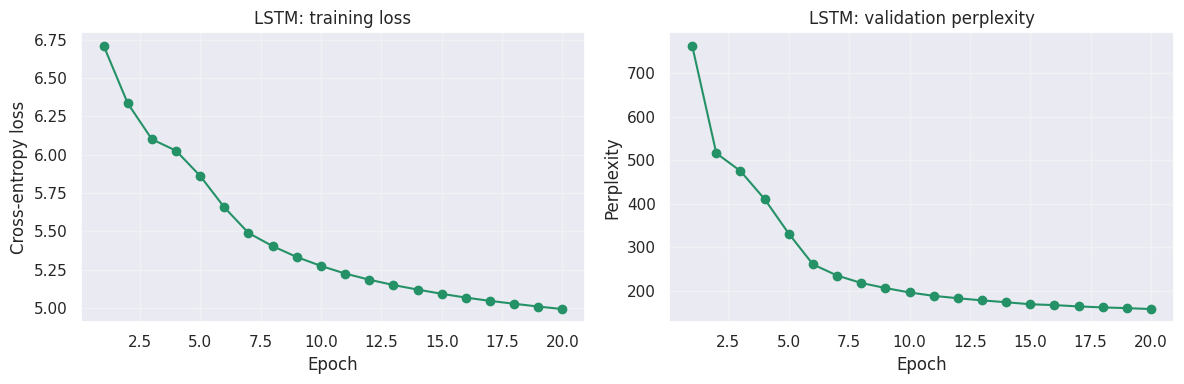

In [40]:
epochs = np.arange(1, len(losses_lstm) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, losses_lstm, marker='o')
axes[0].set_title('LSTM: training loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, perplexities_lstm, marker='o')
axes[1].set_title('LSTM: validation perplexity')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Perplexity')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [46]:
test_perplexity_lstm = evaluate(
    model_lstm,
    criterion,
    test_dataloader,
)

print(f'LSTM test perplexity: {test_perplexity_lstm:.4f}')

LSTM test perplexity: 155.7952


### Второй эксперимент (2 балла)

Попробуйте что-то поменять в модели или в пайплайне обучения, идеи для экспериментов можно подсмотреть выше.

In [41]:
class RNN(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.RNN(hidden_dim, hidden_dim, num_layers = 2, batch_first = True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p = 0.2)

        # Опишите свою нейронную сеть здесь

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        linear = self.linear(output)
        dropout = self.dropout(linear)
        non_linear = self.non_lin(dropout)
        projection = self.projection(non_linear)

        return projection

In [42]:
# Обучите модель здесь
model_rnn = RNN(hidden_dim=hidden_dim, vocab_size=len(word2ind)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer_rnn = torch.optim.Adam(model_rnn.parameters(), lr = lr)

In [43]:
losses_rnn, perplexities_rnn = train_model(
    model=model_rnn,
    criterion=criterion,
    optimizer=optimizer_rnn,
    train_dataloader=train_dataloader,
    eval_dataloader=eval_dataloader,
    num_epochs=num_epochs,
)

Training epoch 1:   0%|          | 0/1243 [00:00<?, ?it/s]

Epoch 1/20 | train loss: 6.7147 | val perplexity: 768.4368


Training epoch 2:   0%|          | 0/1243 [00:00<?, ?it/s]

Epoch 2/20 | train loss: 6.2495 | val perplexity: 401.5788


Training epoch 3:   0%|          | 0/1243 [00:00<?, ?it/s]

Epoch 3/20 | train loss: 5.7358 | val perplexity: 276.0276


... (30 outputs left out)

Training epoch 19:   0%|          | 0/1243 [00:00<?, ?it/s]

Epoch 19/20 | train loss: 5.0092 | val perplexity: 163.5914


Training epoch 20:   0%|          | 0/1243 [00:00<?, ?it/s]

Epoch 20/20 | train loss: 4.9975 | val perplexity: 162.6219


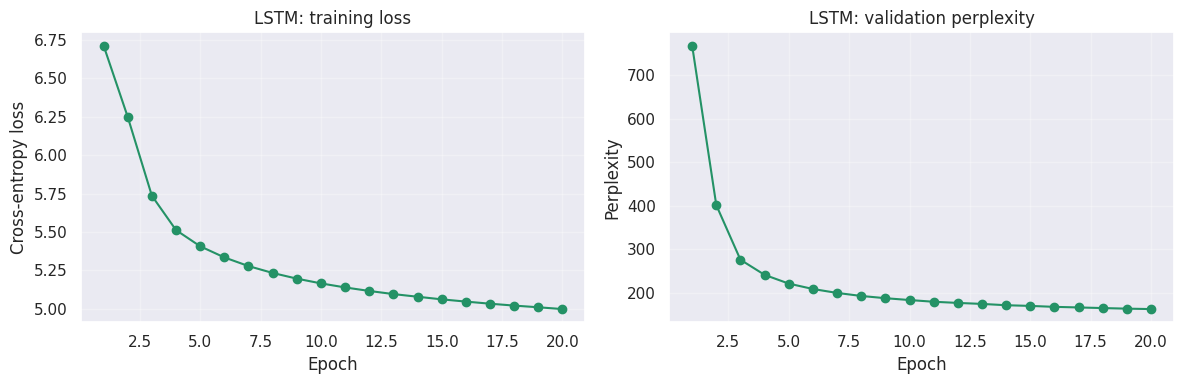

In [44]:
epochs = np.arange(1, len(losses_rnn) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, losses_rnn, marker='o')
axes[0].set_title('LSTM: training loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, perplexities_rnn, marker='o')
axes[1].set_title('LSTM: validation perplexity')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Perplexity')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
test_perplexity_rnn = evaluate(
    model_rnn,
    criterion,
    test_dataloader,
)

print(f'LSTM test perplexity: {test_perplexity_rnn:.4f}')

LSTM test perplexity: 159.6286


In [47]:
class LSTM(nn.Module):
    def __init__(self, hidden_dim: int, vocab_size: int):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, hidden_dim)
        self.rnn = nn.LSTM(hidden_dim, hidden_dim, num_layers = 5, batch_first = True)
        self.linear = nn.Linear(hidden_dim, hidden_dim)
        self.projection = nn.Linear(hidden_dim, vocab_size)

        self.non_lin = nn.Tanh()
        self.dropout = nn.Dropout(p = 0.2)

        # Опишите свою нейронную сеть здесь

    def forward(self, input_batch: torch.Tensor) -> torch.Tensor:
        embeddings = self.embedding(input_batch)
        output, _ = self.rnn(embeddings)
        linear = self.linear(output)
        dropout = self.dropout(linear)
        non_linear = self.non_lin(dropout)
        projection = self.projection(non_linear)

        return projection

In [50]:
hidden_dim = 256
num_epochs = 50
lr = 1e-3

In [52]:
# Обучите модель здесь
model_lstm = LSTM(hidden_dim=hidden_dim, vocab_size=len(word2ind)).to(device)
criterion = nn.CrossEntropyLoss(ignore_index=word2ind['<pad>'])
optimizer_lstm = torch.optim.Adam(model_lstm.parameters(), lr = lr)

losses_lstm, perplexities_lstm = train_model(
    model=model_lstm,
    criterion=criterion,
    optimizer=optimizer_lstm,
    train_dataloader=train_dataloader,
    eval_dataloader=eval_dataloader,
    num_epochs=num_epochs,
)

Training epoch 1:   0%|          | 0/1243 [00:00<?, ?it/s]

Epoch 1/50 | train loss: 6.5128 | val perplexity: 764.0795


Training epoch 2:   0%|          | 0/1243 [00:00<?, ?it/s]

Epoch 2/50 | train loss: 6.3860 | val perplexity: 673.0055


Training epoch 3:   0%|          | 0/1243 [00:00<?, ?it/s]

Epoch 3/50 | train loss: 5.8127 | val perplexity: 220.7226


... (90 outputs left out)

Training epoch 49:   0%|          | 0/1243 [00:00<?, ?it/s]

Epoch 49/50 | train loss: 3.5630 | val perplexity: 304.9498


Training epoch 50:   0%|          | 0/1243 [00:00<?, ?it/s]

Epoch 50/50 | train loss: 3.5540 | val perplexity: 318.9574


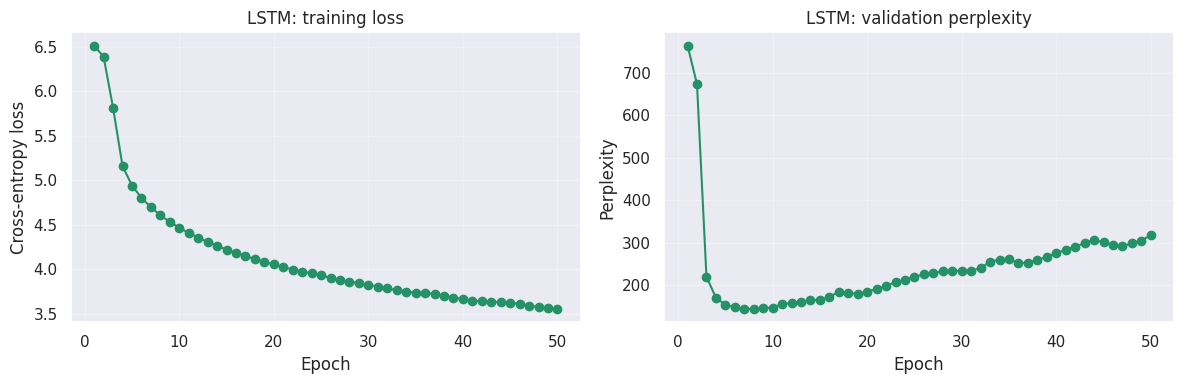

In [53]:
epochs = np.arange(1, len(losses_lstm) + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(epochs, losses_lstm, marker='o')
axes[0].set_title('LSTM: training loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-entropy loss')
axes[0].grid(alpha=0.3)

axes[1].plot(epochs, perplexities_lstm, marker='o')
axes[1].set_title('LSTM: validation perplexity')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Perplexity')
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [54]:
test_perplexity_lstm = evaluate(
    model_lstm,
    criterion,
    test_dataloader,
)

print(f'LSTM test perplexity: {test_perplexity_lstm:.4f}')

LSTM test perplexity: 309.8748


### Отчет (2 балла)

Опишите проведенные эксперименты. Сравните перплексии полученных моделей. Предложите идеи по улучшению качества моделей.